# TP3. Polynômes et fonctions

Carnet de travail. L'énoncé complet, avec les corrigés, est sur le site :
https://cours.gclab.fr/outils-fondamentaux/tp3-polynomes-fonctions/

Exécutez une cellule avec Maj+Entrée. **Pensez à télécharger ce carnet avant de partir** : menu File, puis Download.


## Exercice 1.1 : évaluation naïve

Écrivez `evaluer_naif(P, x)` qui calcule $P(x)$ en suivant la définition, avec une
puissance par terme.

**Résultat attendu :** `evaluer_naif([2, 3, 0, 5], 2)` vaut `48`, car
$2 + 6 + 40 = 48$.


In [1]:
def evaluer_naif(P, x):
    """Évalue le polynôme P au point x, terme par terme."""
    total = 0
    for i in range(len(P)):
        total += P[i]*(x**i)
    return total

print(evaluer_naif([2, 3, 0, 5], 2))
print(evaluer_naif([2, 3, 0, 5], 0))

48
2


## Exercice 2.1 : Horner

Écrivez `evaluer(P, x)` par le schéma de Horner, et vérifiez qu'elle donne le même
résultat que la version naïve sur plusieurs points.

**Résultat attendu :** les deux fonctions coïncident, et Horner est plus rapide sur un
polynôme de degré élevé.


In [2]:
def evaluer(P, x):
    """Évalue le polynôme P au point x par le schéma de Horner."""
    s = 0
    for c in reversed(P):
        s = s*x + c
    return s

P = [2, 3, 0, 5]
for x in (-2, 0, 1, 2, 10):
    print(x, evaluer_naif(P, x), evaluer(P, x))

-2 -44 -44
0 2 2
1 10 10
2 48 48
10 5032 5032


## Exercice 2.2 : mesurer, et se méfier de ses prévisions

Construisez des polynômes dont tous les coefficients valent 1, de degrés 1 000, 5 000
et 20 000, et comparez le temps des deux méthodes en `x = 1.0001`. Avant de lancer la
mesure, écrivez votre prévision : de combien Horner devrait-il être plus rapide ?

**Résultat attendu :** un rapport d'environ 2, **constant** quand le degré augmente.
Ce n'est probablement pas ce que vous aviez prévu.


In [3]:
import time

# Prévision : Horner devrait être beaucoup plus rapide, de plus en plus avec le degré.
for deg in (1000, 5000, 20000):
    P = [1]*(deg + 1)

    t0 = time.perf_counter()
    a = evaluer_naif(P, 1.0001)
    tn = time.perf_counter() - t0

    t0 = time.perf_counter()
    b = evaluer(P, 1.0001)
    th = time.perf_counter() - t0

    print(f"degre {deg:>6} : naif {tn:.5f} s | horner {th:.5f} s "
          f"| rapport {tn / th:.1f} | ecart {abs(a - b):.2e}")
# Rapport constant (~2) : sur un flottant, x ** i coûte un temps constant,
# donc les deux méthodes sont linéaires.

degre   1000 : naif 0.00013 s | horner 0.00005 s | rapport 2.8 | ecart 0.00e+00
degre   5000 : naif 0.00044 s | horner 0.00023 s | rapport 1.9 | ecart 0.00e+00
degre  20000 : naif 0.00364 s | horner 0.00096 s | rapport 3.8 | ecart 7.28e-12


## Exercice 2.3 : le cas où l'écart explose vraiment

Refaites la mesure en évaluant en `x = 3`, un **entier**, sur des degrés 200, 400
et 800. Le rapport reste-t-il constant ?

**Résultat attendu :** cette fois le rapport grandit avec le degré, d'environ 4 à
environ 6.


In [4]:
for deg in (200, 400, 800):
    P = [1]*(deg + 1)

    t0 = time.perf_counter()
    a = evaluer_naif(P, 3)
    tn = time.perf_counter() - t0

    t0 = time.perf_counter()
    b = evaluer(P, 3)
    th = time.perf_counter() - t0

    print(f"degre {deg:>4} : rapport {tn / th:.1f} | egaux : {a == b}")
# Sur des entiers, 3 ** i est calculé exactement et grossit avec i :
# le coût de la version naïve croît vraiment avec le degré.

degre  200 : rapport 3.7 | egaux : True
degre  400 : rapport 4.3 | egaux : True
degre  800 : rapport 6.0 | egaux : True


## Exercice 3.1 : la dérivée

Écrivez `deriver(P)` qui renvoie la liste des coefficients du polynôme dérivé.

**Résultat attendu :** `deriver([2, 3, 0, 5])` vaut `[3, 0, 15]`, c'est-à-dire
$3 + 15x^{2}$.


In [5]:
def deriver(P):
    """Coefficients du polynôme dérivé de P."""
    return [i * P[i] for i in range(1, len(P))]

print(deriver([2, 3, 0, 5]))
print(deriver([7]), evaluer(deriver([7]), 3))

[3, 0, 15]
[] 0


## Exercice 4.1 : dichotomie

Écrivez `dichotomie(f, a, b, tolerance)` qui renvoie une racine de `f` entre `a` et
`b`. Appliquez-la à $x^{2} - 2$ sur $[0, 2]$.

**Résultat attendu :** une valeur proche de $\sqrt{2} \approx 1{,}414214$.


In [6]:
def dichotomie(f, a, b, tol=1e-12):
    """Racine de f dans [a, b] par bissection ; f(a) et f(b) de signes opposés."""
    fa, fb = f(a), f(b)
    if fa == 0:
        return a
    if fb == 0:
        return b
    if fa * fb > 0:
        raise ValueError("f(a) et f(b) doivent etre de signes opposes")
    while b - a > tol:
        m = (a + b) / 2
        if f(a) * f(m) <= 0:
            b = m
        else:
            a = m
    return (a + b) / 2

def f(x):
    return x * x - 2

r = dichotomie(f, 0, 2)
print(r)
print(abs(r - 2 ** 0.5) < 1e-9)

1.414213562372879
True


## Exercice 4.2 : Newton sur un polynôme

Écrivez `newton(P, depart, tolerance)` qui cherche une racine du polynôme `P` en
utilisant `evaluer` et `deriver`. Appliquez-la à $x^{3} - 2x - 5$, en partant de 2.

**Résultat attendu :** environ `2.0945515`, atteint en cinq tours ou moins.


In [7]:
def newton(P, depart, tol=1e-12, max_tours=100):
    """Racine du polynôme P par la méthode de Newton, à partir de depart."""
    dP = deriver(P)
    x = float(depart)
    for k in range(max_tours):
        pente = evaluer(dP, x)
        if pente == 0:
            raise ZeroDivisionError("tangente horizontale")
        y = x - evaluer(P, x) / pente
        if abs(y - x) <= tol * max(1.0, abs(y)):
            return y, k + 1
        x = y
    raise RuntimeError(f"pas de convergence en {max_tours} tours")

Q = [-5, -2, 0, 1]  # x^3 - 2x - 5
r, k = newton(Q, 2)
print(r, "en", k, "tours")
print(abs(evaluer(Q, r)) < 1e-10)

2.0945514815423265 en 5 tours
True


## Exercice 4.3 : faire échouer Newton

Appliquez `newton` au polynôme $x^{3} - 2x + 2$, c'est-à-dire `[2, -2, 0, 1]`, en
partant de `0`. Affichez le trajet des premiers itérés pour comprendre ce qui se passe.

**Résultat attendu :** aucune convergence, et un trajet qui alterne entre `0` et `1`
indéfiniment.


In [8]:
def newton_trace(P, depart, tours):
    """Liste des premiers itérés de Newton, sans test d'arrêt."""
    dP = deriver(P)
    x = float(depart)
    trajet = [x]
    for _ in range(tours):
        pente = evaluer(dP, x)
        if pente == 0:
            break
        x = x - evaluer(P, x) / pente
        trajet.append(x)
    return trajet

R = [2, -2, 0, 1]  # x^3 - 2x + 2
print(newton_trace(R, 0, 8))

try:
    print(newton(R, 0))
except RuntimeError as e:
    print("echec :", e)
# Cycle 0 -> 1 -> 0 -> ... : sans max_tours, la boucle serait infinie.

[0.0, 1.0, 0.0, 1.0, 0.0, 1.0, 0.0, 1.0, 0.0]
echec : pas de convergence en 100 tours


## Exercice 4.4 : le prix d'un mauvais point de départ

Reprenez $x^{3} - 2x - 5$ et comparez le nombre de tours de `newton` en partant
de `2`, puis de `0`.

**Résultat attendu :** cinq tours depuis `2`, une vingtaine depuis `0`.


In [9]:
Q = [-5, -2, 0, 1]
for x0 in (2, 1, 0):
    r, k = newton(Q, x0)
    print(f"depart {x0:>2} : {k:>2} tours, racine {r:.9f}")

depart  2 :  5 tours, racine 2.094551482
depart  1 : 10 tours, racine 2.094551482
depart  0 : 20 tours, racine 2.094551482


## Exercice 5.1 : lire le graphique

Sur le tracé, repérez la racine trouvée par Newton. Combien de fois la courbe
coupe-t-elle l'axe des abscisses ? Ce polynôme est de degré 3 : que dire de ses autres
racines ?


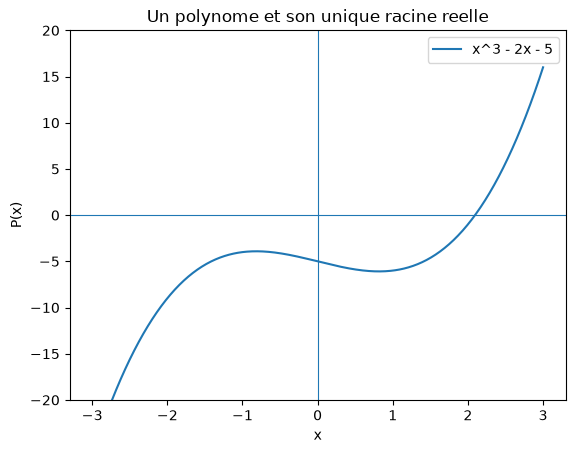

In [10]:
import matplotlib.pyplot as plt

Q = [-5, -2, 0, 1]  # x^3 - 2x - 5
xs = [i / 100 for i in range(-300, 301)]
ys = [evaluer(Q, x) for x in xs]

plt.figure()
plt.plot(xs, ys, label="x^3 - 2x - 5")
plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)
plt.ylim(-20, 20)
plt.xlabel("x")
plt.ylabel("P(x)")
plt.legend()
plt.title("Un polynome et son unique racine reelle")
plt.show()

# La courbe coupe l'axe une seule fois, vers 2.0945 (la racine de Newton).
# Degré 3 : trois racines dans les complexes ; les deux autres sont
# complexes conjuguées, donc invisibles sur un tracé réel.

## Exercice 6.1 : somme et produit

Écrivez `somme(P, Q)` et `produit_poly(P, Q)`. Attention, les deux listes n'ont pas
forcément la même longueur.

**Résultat attendu :** `produit_poly([1, 1], [1, 1])` vaut `[1, 2, 1]`, c'est-à-dire
$(1 + x)^{2} = 1 + 2x + x^{2}$, et `produit_poly([-1, 1], [1, 1])` vaut
`[-1, 0, 1]`, l'identité $(x - 1)(x + 1) = x^{2} - 1$.


In [11]:
def somme(P, Q):
    """Somme de deux polynômes."""
    n = max(len(P), len(Q))
    P = P + [0] * (n - len(P))
    Q = Q + [0] * (n - len(Q))
    return [P[i] + Q[i] for i in range(n)]

def produit_poly(P, Q):
    """Produit de deux polynômes."""
    if not P or not Q:
        return []
    R = [0] * (len(P) + len(Q) - 1)
    for i in range(len(P)):
        for j in range(len(Q)):
            R[i + j] = R[i + j] + P[i] * Q[j]
    return R

print(somme([1, 2], [0, 0, 3]))
print(produit_poly([1, 1], [1, 1]))
print(produit_poly([-1, 1], [1, 1]))
# vérification par évaluation en un point
P, Q = [1, 2], [0, 0, 3]
print(evaluer(produit_poly(P, Q), 1.5) == evaluer(P, 1.5) * evaluer(Q, 1.5))

[1, 2, 3]
[1, 2, 1]
[-1, 0, 1]
True


## Exercice 6.2 : le triangle de Pascal, par les polynômes

Calculez $(1 + x)^{10}$ en multipliant dix fois `[1, 1]` par lui-même. Que
reconnaissez-vous dans la liste obtenue ?

**Résultat attendu :** `[1, 10, 45, 120, 210, 252, 210, 120, 45, 10, 1]`.


In [12]:
b = [1]
for _ in range(10):
    b = produit_poly(b, [1, 1])
print(b)
print(sum(b), 2 ** 10)
# Coefficients binomiaux : 10e ligne du triangle de Pascal.

[1, 10, 45, 120, 210, 252, 210, 120, 45, 10, 1]
1024 1024


## Exercice 7.1 : trouver le meilleur pas

Écrivez `derivee_avant(f, x, h)` et `derivee_centree(f, x, h)`. Calculez l'erreur de
chacune sur $\sin$ en $x = 1$, dont la dérivée exacte est $\cos 1$, pour
`h` valant $10^{-1}, 10^{-2}, 10^{-4}, 10^{-6}, 10^{-8}, 10^{-10}, 10^{-12}$.

**Résultat attendu :** l'erreur diminue puis **remonte**. Le meilleur pas est de
l'ordre de $10^{-8}$ pour la formule avant, $10^{-6}$ pour la formule centrée,
et à $h = 10^{-12}$ l'erreur est remontée de quatre à six ordres de grandeur
par rapport à ce meilleur pas.


In [13]:
import math

def derivee_avant(f, x, h):
    return (f(x + h) - f(x)) / h

def derivee_centree(f, x, h):
    return (f(x + h) - f(x - h)) / (2 * h)

ex = math.cos(1.0)
for h in (1e-1, 1e-2, 1e-4, 1e-6, 1e-8, 1e-10, 1e-12):
    ea = abs(derivee_avant(math.sin, 1.0, h) - ex)
    ec = abs(derivee_centree(math.sin, 1.0, h) - ex)
    print(f"h = {h:.0e} : avant {ea:.1e} | centree {ec:.1e}")

h = 1e-01 : avant 4.3e-02 | centree 9.0e-04
h = 1e-02 : avant 4.2e-03 | centree 9.0e-06
h = 1e-04 : avant 4.2e-05 | centree 9.0e-10
h = 1e-06 : avant 4.2e-07 | centree 2.8e-11
h = 1e-08 : avant 3.0e-09 | centree 2.6e-09
h = 1e-10 : avant 5.8e-08 | centree 5.8e-08
h = 1e-12 : avant 4.3e-05 | centree 1.2e-05


## Exercice 8.1 : les trois méthodes

Écrivez `rectangles(f, a, b, n)`, `trapezes(f, a, b, n)` et `simpson(f, a, b, n)`.
Testez-les sur $\int_0^1 x^{2}\,dx = 1/3$ pour `n` valant 10, 100 et 1000.

**Résultat attendu :** l'erreur des rectangles est divisée par 10 quand `n` est
multiplié par 10, celle des trapèzes par 100, et Simpson donne le résultat exact, à
un arrondi de $10^{-17}$ près.


In [14]:
def rectangles(f, a, b, n):
    """Intégrale de f sur [a, b] par n rectangles à gauche."""
    h = (b - a) / n
    return h * sum(f(a + i * h) for i in range(n))

def trapezes(f, a, b, n):
    """Intégrale de f sur [a, b] par n trapèzes."""
    h = (b - a) / n
    s = sum(f(a + i * h) for i in range(1, n))
    return h * ((f(a) + f(b)) / 2 + s)

def simpson(f, a, b, n):
    """Intégrale de f sur [a, b] par Simpson (n rendu pair)."""
    if n % 2 == 1:
        n = n + 1
    h = (b - a) / n
    imp = sum(f(a + i * h) for i in range(1, n, 2))
    pai = sum(f(a + i * h) for i in range(2, n, 2))
    return h / 3 * (f(a) + f(b) + 4 * imp + 2 * pai)

def carre(x):
    return x * x

for n in (10, 100, 1000):
    er = abs(rectangles(carre, 0, 1, n) - 1 / 3)
    et = abs(trapezes(carre, 0, 1, n) - 1 / 3)
    es = abs(simpson(carre, 0, 1, n) - 1 / 3)
    print(f"n = {n:>4} : rectangles {er:.1e} | trapezes {et:.1e} | simpson {es:.1e}")

n =   10 : rectangles 4.8e-02 | trapezes 1.7e-03 | simpson 0.0e+00
n =  100 : rectangles 5.0e-03 | trapezes 1.7e-05 | simpson 5.6e-17
n = 1000 : rectangles 5.0e-04 | trapezes 1.7e-07 | simpson 0.0e+00


## Exercice 8.2 : calculer π

On a $\int_0^1 \frac{4}{1 + x^{2}}\,dx = \pi$. Calculez cette intégrale par les
trapèzes et par Simpson avec `n = 1000`, et comparez à `math.pi`.

**Résultat attendu :** une erreur de l'ordre de $10^{-7}$ pour les trapèzes, et
un résultat indistinguable de `math.pi` pour Simpson.


In [15]:
def g(x):
    return 4 / (1 + x * x)

pt = trapezes(g, 0, 1, 1000)
ps = simpson(g, 0, 1, 1000)
print(pt, abs(pt - math.pi))
print(ps, abs(ps - math.pi))

3.141592486923127 1.6666666624587378e-07
3.141592653589793 0.0


## L'IA vous le donne en trois secondes

**Polynôme.** J'ai posé la question à un assistant IA, puis j'ai exécuté le code qu'il proposait pour vérifier ses affirmations.

Il donne directement Horner, pas la version naïve. Pour le degré 20 000, il annonce un gain de 1,5 à 3 seulement, car `x ** k` sur un flottant coûte un temps constant : c'est cohérent avec ma mesure de l'exercice 2.2 (rapport entre 2 et 4, constant). En revanche, il affirme que `numpy.polyval` serait au moins 10 fois plus rapide, et c'est faux : mesuré, il est environ 26 fois plus lent que Horner en Python pur (14 ms contre 0,55 ms). Il avait précisé ne pas avoir mesuré : seule la mesure tranche.